# MOD10 · Class 5 — Unsupervised clustering with K-Means

**Members of Group :** Adrien ROUILLON, Paul MORAND

**Data set :** Spotify

## Étape 0 – Execute code



---

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/Adrien-Rouillon/Machine-learning---SpotifyDB/refs/heads/main/spotify_artist_streaming_2020_2025.csv"
df = pd.read_csv(url)


In [51]:
def add_noise(df, seed=42):  # return a messy copy of a clean DataFrame
    rng = np.random.default_rng(seed)  # fixed seed -> same mess every run
    out = df.copy(deep=True)  # work on a deep copy so df is never modified
    num_cols = out.select_dtypes("number").columns.tolist()  # numeric columns available to corrupt
    if len(num_cols) < 2:  # need at least two numeric columns
        raise ValueError("df needs at least 2 numeric columns")  # fail loudly instead of guessing
    miss_cols = num_cols[:2]  # first two numeric columns get missing values
    out_col = num_cols[0]  # first numeric column gets outliers
    text_col = num_cols[2] if len(num_cols) > 2 else num_cols[1]  # third (or second) becomes text
    n = len(out)  # number of original rows

    # --- extreme outliers ---
    out_idx = rng.choice(out.index, size=3, replace=False)  # pick 3 rows to corrupt
    col = out[out_col].astype(float)  # float copy so large values fit
    col.loc[out_idx] = col.mean() + 20 * col.std() * rng.choice([-1, 1], size=3)  # push Â±20 std from the mean
    out[out_col] = col  # write outliers back

    # --- ~5% missing values in two numeric columns ---
    for c in miss_cols:  # handle each target column
        nan_idx = rng.choice(out.index, size=max(1, round(0.05 * n)), replace=False)  # 5% random rows
        out[c] = out[c].astype(float)  # ints can't hold NaN, so cast to float
        out.loc[nan_idx, c] = np.nan  # blank them out

    # --- inconsistent categorical column ---
    base = rng.choice(["Red", "Green", "Blue"], size=n)  # clean underlying categories
    variants = [str.lower, str.upper, str.title, lambda s: f" {s}", lambda s: f"{s}  "]  # case/spacing styles
    out["color"] = [variants[rng.integers(len(variants))](v) for v in base]  # apply a random style per row

    # --- numeric column stored as text with a stray 'unknown' ---
    out[text_col] = out[text_col].map(lambda v: "" if pd.isna(v) else str(v)).astype(object)  # numbers -> strings
    out.loc[rng.choice(out.index), text_col] = "unknown"  # one non-numeric token

    # --- 5 exact duplicate rows ---
    dup_rows = out.loc[rng.choice(out.index, size=5, replace=False)]  # copy 5 existing (already messy) rows
    out = pd.concat([out, dup_rows], ignore_index=True)  # append them -> exact duplicates
    out = out.sample(frac=1, random_state=seed).reset_index(drop=True)  # shuffle so dupes aren't at the end

    return out  # the messy copy

df = add_noise(df)

In [52]:

print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()


df = df.dropna(subset=["popularity"])

df = df[df["duration_ms"].isna() | df["duration_ms"].between(30_000, 900_000)]

df["duration_ms"] = df["duration_ms"].fillna(df["duration_ms"].median())

df["danceability"] = pd.to_numeric(df["danceability"], errors="coerce")
df = df.dropna(subset=["danceability"])

print(df.shape)
print("popularity max:", df["popularity"].max())


Duplicates: 5
(47497, 34)
popularity max: 92.0


In [53]:
to_drop = [
    "track_name", "album_name", "artist_name", "release_date",              #text with unique value
    "popularity_category",                                                  #Leak : popularity drift
    "duration_minutes", "key_name", "mode_name", "is_explicit_bool",
    "loudness_category", "release_quarter", "log_stream_count",             #doubles
    "index", "track_id","color", "label", "is_weekend_release",
    "release_day_of_week", "country"
]

df = df.drop(columns=[c for c in to_drop if c in df.columns])

bool_map = {True:1,False:0,"true":1,"false":0,"True":1,"False":0}

for c in ["genre"]:
    df[c] = df[c].map(str.lower)


df["key"] = df["key"].map(lambda x: f"key_{x}")

df = pd.get_dummies(df, columns=["key", "genre"],
                    drop_first=True, dtype=int)

## Étape 1 – Features



---

We already droped all the data that can identify the line, so in this step we just have to droped the target.

In [54]:
df.drop(columns=['popularity','stream_count'])

,duration_ms,danceability,energy,loudness,mode,instrumentalness,tempo,stream_count,explicit,release_year,...,genre_k-pop,genre_latin,genre_metal,genre_pop,genre_punk,genre_r&b,genre_reggaeton,genre_rock,genre_soul,genre_trap
0,178551.0,0.6422,0.6088,-9.76,1,0.0020,130.24,16416,True,2020,...,0,0,0,1,0,0,0,0,0,0
1,209647.0,0.6503,0.5237,-6.02,1,0.0653,115.25,2880,False,2022,...,0,0,0,1,0,0,0,0,0,0
2,226433.0,0.5826,0.8425,-6.02,0,0.0832,93.51,27074,False,2022,...,0,0,0,1,0,0,0,0,0,0
3,204174.0,0.5797,0.4981,-11.41,0,0.0194,132.61,17388,False,2020,...,0,0,0,0,0,0,0,0,1,0
4,202885.0,0.7227,0.3697,-10.87,0,0.0023,110.94,9728,True,2021,...,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49999,212672.0,0.5558,0.8448,0.00,1,0.3662,126.80,38256,True,2025,...,0,0,1,0,0,0,0,0,0,0
50001,250850.0,0.8514,0.5398,-9.44,1,0.0148,94.82,482205,False,2022,...,0,0,0,0,0,1,0,0,0,0
50002,209647.0,0.6271,0.6988,-6.91,1,0.0251,98.67,31641,False,2021,...,0,0,0,1,0,0,0,0,0,0
50003,243915.0,0.6995,0.5238,-8.66,1,0.0180,104.81,5628,False,2025,...,0,0,0,0,0,0,0,0,0,0


So now we just have to keep the data that are interesting to regroupe musics (for example danceability, loudness, ...) because some of this data can be related example music that have high danceability can have probably high loudness.

## Étape 2 – Scaling



---

In [55]:
from sklearn.preprocessing import StandardScaler
X = df
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Shape after scaling :", X_scaled.shape)

Shape after scaling : (47497, 44)


## Étape 3 – Choose k — the *elbow*



---

k=2 | Inertia: 1980077 | Silhouette: 0.0584
k=3 | Inertia: 1900628 | Silhouette: 0.0328
k=4 | Inertia: 1834599 | Silhouette: 0.0384
k=5 | Inertia: 1779039 | Silhouette: 0.0547
k=6 | Inertia: 1731827 | Silhouette: 0.0658
k=7 | Inertia: 1660522 | Silhouette: 0.0623
k=8 | Inertia: 1629215 | Silhouette: 0.0813


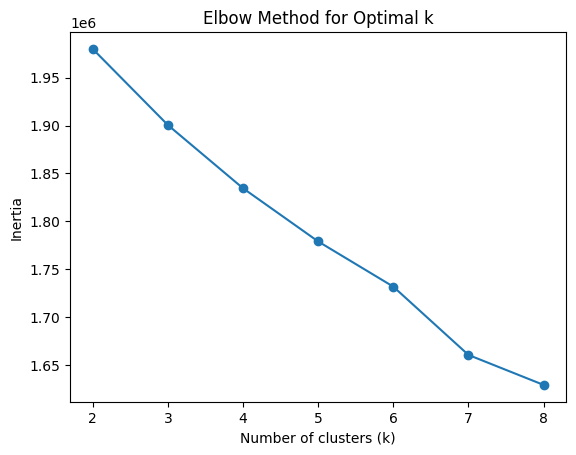

In [56]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
  km = KMeans(n_clusters=k, n_init=10, random_state=42)
  labels = km.fit_predict(X_scaled)
  inertias.append(km.inertia_)
  silhouettes.append(
      silhouette_score(X_scaled, labels, sample_size=10000, random_state=42)
  )

for k, iner, sil in zip(K_range, inertias, silhouettes):
  print(f"k={k} | Inertia: {iner:.0f} | Silhouette: {sil:.4f}")

plt.plot(K_range, inertias, "-o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

So has we can see, each musics have its own particularity

## Étape 4 – Fit K-Means



---

In [57]:
km =KMeans(n_clusters=3, n_init=10, random_state = 42).fit(X_scaled)
clusters = km.fit_predict(X_scaled)
print(np.bincount(clusters))

[31196  3277 13024]


In [58]:
prof = X.copy()
prof["cluster"] = clusters
print(prof.groupby("cluster").mean().round(1))

         duration_ms  popularity  danceability  energy  loudness  mode  \
cluster                                                                  
0           209585.3        28.2           0.7     0.7      -7.0   0.7   
1           209158.1        27.9           0.4     0.3     -10.5   0.6   
2           210272.5        28.1           0.7     0.5      -8.6   0.6   

         instrumentalness  tempo  stream_count  explicit  ...  genre_k-pop  \
cluster                                                   ...                
0                     0.1  123.9      123575.3       0.2  ...          0.0   
1                     0.2  110.2      105763.9       0.3  ...          0.0   
2                     0.0  109.8      109370.0       0.2  ...          0.0   

         genre_latin  genre_metal  genre_pop  genre_punk  genre_r&b  \
cluster                                                               
0                0.1          0.1        0.4         0.0        0.0   
1                0.0     